# Day 11 · Machine learning in computer vision: kNN and SVM on handwritten digits

**Course lab:** `CV-Week2-Lecture4.ipynb` (Day 11: Introduction to ML in CV)
**Notes chapter:** `week-2/notes/04_ml_in_cv_knn_svm.md`
**Run time:** about 2 minutes on a laptop CPU (the MNIST timing experiment in section 7 is the slow part, about 1 minute).

**What you will learn**
- Why we *learn* a classifier from examples instead of writing rules by hand.
- How **k-Nearest Neighbours (kNN)** and **Support Vector Machines (SVM)** classify an image.
- How to read a `classification_report` (precision, recall, f1-score, support) and a confusion matrix.
- What `n_neighbors`, `kernel`, `C` and `gamma` actually do, with experiments.
- How to build a digit recogniser that works on a digit **you draw yourself**, and the preprocessing that makes it work.

Every code cell from the course notebook is here, with the same names and calls, explained line by line. Where the course code had a bug or a misleading test, we fix it and say why (section 9).

## 1 · The idea in plain language

**Hand-written rules do not scale.** Try writing an `if` statement that recognises a "7" from pixel values: every person writes it differently. Machine learning flips the job around: we give the computer **many labelled examples** ("this picture is a 7") and it works out the rule itself. This is **supervised learning**: input → label → prediction.

To a classical ML model an image is just a **list of numbers** (a *feature vector*). An 8×8 grey image becomes 64 numbers, one per pixel. Two images of the same digit should give "nearby" lists of numbers.

### kNN: "ask your neighbours"
> You move to a new town and want to know which football team to support. You ask your **5 nearest neighbours** and go with the majority.

kNN does exactly that. To classify a new image it:
1. measures the **distance** (usually Euclidean, straight-line distance in 64-D space) from the new image to **every** training image,
2. picks the **k** closest ones (`n_neighbors=k`),
3. takes a **majority vote** of their labels.

There is no real training: `fit()` just stores the data. All the work happens at prediction time, which is why kNN gets slower as the training set grows.

### SVM: "draw the widest street between the classes"
> Imagine red and blue marbles on a table. An SVM lays a ruler (a line, or in many dimensions a *hyperplane*) between them so that the **gap (margin) on each side is as wide as possible**. The marbles that touch the edge of the street are the **support vectors**; they alone decide where the street goes.

- `kernel='linear'`: the street is straight.
- `kernel='rbf'`: the **kernel trick** lets the boundary curve around groups of points, by implicitly mapping the data into a higher-dimensional space.
- `C` = how strict the SVM is about training mistakes. Large `C` → tries hard to classify every training point correctly (narrow street, risk of overfitting). Small `C` → allows some mistakes for a wider, smoother street.
- `gamma` (RBF only) = how far the influence of one training point reaches. Large `gamma` → very local, wiggly boundary; small `gamma` → smooth boundary. **A linear kernel has no `gamma`.**

SVMs handle 10 classes by training many two-class SVMs (scikit-learn's `SVC` uses **one-vs-one**: 45 little SVMs, one per pair of digits, which then vote).

## 2 · Setup

Install once from a terminal: `pip install scikit-learn matplotlib opencv-python torch torchvision` (torch/torchvision are only needed for the MNIST experiment in section 7; the rest works without them).

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import cv2
import sklearn
from threadpoolctl import threadpool_limits

threadpool_limits(2)          # optional: use at most 2 CPU cores so the laptop stays responsive
np.random.seed(0)
plt.rcParams["figure.dpi"] = 80
print("scikit-learn", sklearn.__version__, "| OpenCV", cv2.__version__)

scikit-learn 1.9.1 | OpenCV 5.0.0


## 3 · The course code: load the digits, split, look at one

This is the course cell, unchanged apart from comments. One correction to the course comment: `datasets.load_digits()` is **not MNIST**. It is the small **UCI optical digits** set that ships inside scikit-learn: 1,797 images of **8×8 pixels**, with values from **0 to 16** (how many "ink" pixels fell into each 4×4 block of an original 32×32 scan). Real MNIST is 70,000 images of 28×28 pixels with values 0–255; we use it in section 7 and on Day 15.

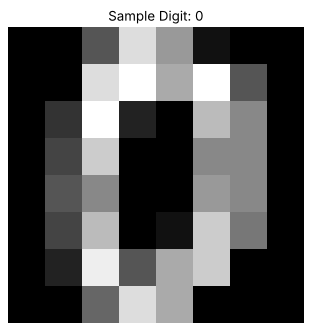

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

# Load the scikit-learn digits dataset (8x8 images, values 0-16; NOT the 28x28 MNIST)
digits = datasets.load_digits()
X = digits.images.reshape((len(digits.images), -1))   # (1797, 8, 8) -> (1797, 64): each image becomes a row of 64 numbers
y = digits.target                                      # the true label 0-9 of each image

# Split into train and test: 70% to learn from, 30% kept aside to measure honest accuracy
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Show sample digit
plt.imshow(digits.images[0], cmap='gray')
plt.title(f"Sample Digit: {digits.target[0]}")
plt.axis('off')
plt.show()

images: (1797, 8, 8) -> feature matrix X: (1797, 64)
pixel value range: 0.0 to 16.0
train: (1257, 64)  test: (540, 64)
images per class in the test set: [53 50 47 54 60 66 53 55 43 59]


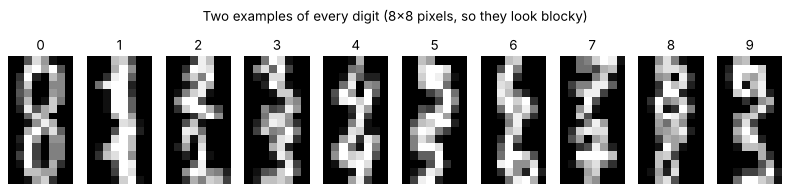

The first digit as the 8x8 grid of numbers the classifier sees:
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]


In [3]:
print("images:", digits.images.shape, "-> feature matrix X:", X.shape)
print("pixel value range:", X.min(), "to", X.max())
print("train:", X_train.shape, " test:", X_test.shape)
print("images per class in the test set:", np.bincount(y_test))

fig, axes = plt.subplots(2, 10, figsize=(10, 2.4))
for d in range(10):
    for r in range(2):
        idx = np.where(y == d)[0][r]
        axes[r, d].imshow(digits.images[idx], cmap='gray'); axes[r, d].axis('off')
    axes[0, d].set_title(str(d))
plt.suptitle("Two examples of every digit (8x8 pixels, so they look blocky)"); plt.tight_layout(); plt.show()

print("The first digit as the 8x8 grid of numbers the classifier sees:")
print(digits.images[0].astype(int))

**Line by line**
- `reshape((len(digits.images), -1))` flattens each 8×8 image into 64 numbers. `-1` means "work this size out for me". kNN and SVM need one flat row per sample.
- `train_test_split(..., test_size=0.3, random_state=42)` shuffles and holds back 30% (540 images) for testing. The model never sees them during training, so the test score estimates how it does on **new** images. `random_state=42` makes the shuffle repeatable.
- In the grid of numbers, 0 = background and 16 = full ink. With `cmap='gray'` that shows as a **white digit on a black background**; remember this for the mini project.

## 4 · Exercise: classify digits with kNN (course code)

In [4]:
# Train kNN classifier
knn = KNeighborsClassifier(n_neighbors=5)   # vote among the 5 closest training images
knn.fit(X_train, y_train)                   # "training" = just storing X_train and y_train
y_pred_knn = knn.predict(X_test)            # for each test image: distances to all 1257 training images, top-5 vote

print("kNN Classification Report:")
print(classification_report(y_test, y_pred_knn))

kNN Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        53
           1       1.00      1.00      1.00        50
           2       1.00      1.00      1.00        47
           3       0.98      1.00      0.99        54
           4       0.98      1.00      0.99        60
           5       0.98      0.98      0.98        66
           6       1.00      1.00      1.00        53
           7       1.00      1.00      1.00        55
           8       1.00      1.00      1.00        43
           9       0.98      0.95      0.97        59

    accuracy                           0.99       540
   macro avg       0.99      0.99      0.99       540
weighted avg       0.99      0.99      0.99       540



### How to read a `classification_report` (examiners love this)

Take one row, say digit **9**. Out of all test images:
- **precision** = of the images the model *called* "9", what fraction really were 9? ("When it says 9, can I trust it?")  precision = TP / (TP + FP)
- **recall** = of the images that really *are* 9, what fraction did the model find? ("Did it miss any 9s?")  recall = TP / (TP + FN)
- **f1-score** = the harmonic mean of the two, 2·P·R / (P + R). It is high only if **both** are high.
- **support** = how many test images of that class there are (it is a count, not a score).

The bottom rows: **accuracy** = correct / total over all classes; **macro avg** = plain average over the 10 classes (each class counts equally); **weighted avg** = average weighted by support (bigger classes count more).

TP = true positives, FP = false positives (wrongly called 9), FN = false negatives (a real 9 called something else).

A **confusion matrix** shows the same information as a grid: row = true digit, column = predicted digit. Everything off the diagonal is a mistake.

kNN test accuracy: 0.9926  (4 mistakes out of 540)


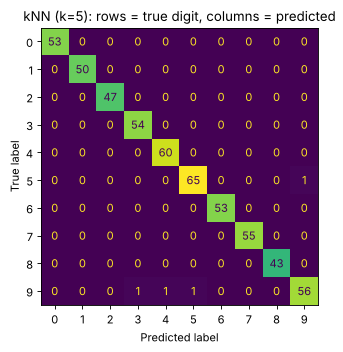

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score

print(f"kNN test accuracy: {accuracy_score(y_test, y_pred_knn):.4f}  "
      f"({(y_pred_knn != y_test).sum()} mistakes out of {len(y_test)})")
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_knn)).plot(ax=ax, colorbar=False)
ax.set_title("kNN (k=5): rows = true digit, columns = predicted"); plt.tight_layout(); plt.show()

## 5 · Exercise: classify digits with SVM (course code, fixed)

The course wrote `SVC(kernel='linear', gamma='scale')`. **`gamma` does nothing for a linear kernel**: it is a parameter of the RBF, polynomial and sigmoid kernels only. scikit-learn silently ignores it, so the code runs, but it suggests a setting that is not being used. We prove that below, then use the clean version.

In [6]:
# Proof that gamma is ignored by a linear kernel: wildly different gamma, identical model
a = SVC(kernel='linear', gamma='scale').fit(X_train, y_train)
b = SVC(kernel='linear', gamma=1000.0).fit(X_train, y_train)
print("Same predictions with gamma='scale' and gamma=1000?", np.array_equal(a.predict(X_test), b.predict(X_test)))
print("Same support vectors?", np.array_equal(a.support_, b.support_))

Same predictions with gamma='scale' and gamma=1000? True
Same support vectors? True


In [7]:
# Train SVM classifier (course code with the meaningless gamma removed)
svm = SVC(kernel='linear')        # straight-line (hyperplane) boundaries, C=1.0 by default
svm.fit(X_train, y_train)         # finds the widest-margin boundary for every pair of digits (one-vs-one)
y_pred_svm = svm.predict(X_test)

print("SVM Classification Report:")
print(classification_report(y_test, y_pred_svm))
print(f"linear SVM test accuracy: {accuracy_score(y_test, y_pred_svm):.4f}  "
      f"| support vectors kept: {svm.n_support_.sum()} of {len(X_train)} training images")

SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        53
           1       0.98      0.98      0.98        50
           2       0.98      1.00      0.99        47
           3       1.00      0.96      0.98        54
           4       0.98      0.98      0.98        60
           5       0.97      0.97      0.97        66
           6       1.00      1.00      1.00        53
           7       0.96      0.98      0.97        55
           8       0.95      0.98      0.97        43
           9       0.97      0.95      0.96        59

    accuracy                           0.98       540
   macro avg       0.98      0.98      0.98       540
weighted avg       0.98      0.98      0.98       540

linear SVM test accuracy: 0.9796  | support vectors kept: 374 of 1257 training images


`n_support_` shows the "widest street" idea in action: only the training images near a boundary are kept as support vectors; the rest could be deleted without changing the model.

### Linear vs RBF kernel

The RBF kernel is scikit-learn's default (`SVC()` with no arguments). Let us compare it fairly with the linear one on the same split.

In [8]:
svm_rbf = SVC(kernel='rbf', gamma='scale', C=1.0).fit(X_train, y_train)   # gamma DOES matter here
y_pred_rbf = svm_rbf.predict(X_test)
for name, pred in [("kNN (k=5)", y_pred_knn), ("SVM linear", y_pred_svm), ("SVM RBF", y_pred_rbf)]:
    print(f"{name:12s} accuracy = {accuracy_score(y_test, pred):.4f}   mistakes = {(pred != y_test).sum()}")
print("gamma='scale' works out to", round(1 / (X_train.shape[1] * X_train.var()), 5), "for this data")

kNN (k=5)    accuracy = 0.9926   mistakes = 4
SVM linear   accuracy = 0.9796   mistakes = 11
SVM RBF      accuracy = 0.9870   mistakes = 7
gamma='scale' works out to 0.00043 for this data


**Careful:** with only 540 test images, a difference of 2–3 mistakes is about 0.5% and could flip with a different random split. To compare models properly we use **cross-validation** (next section): split the training data 5 different ways and average.

## 6 · Experiments: what do the parameters do?

### 6a · Choosing k for kNN

We pick `k` using **5-fold cross-validation on the training set only**, so the test set stays untouched. (Choosing k by looking at test accuracy would be cheating: the test set would no longer be "unseen".)

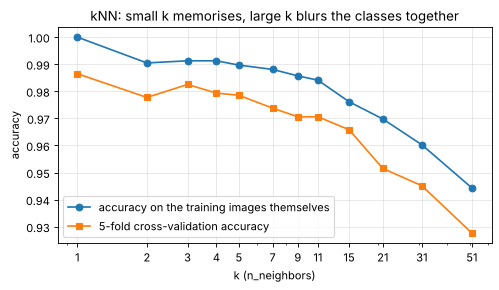

k= 1: CV accuracy 0.9865
k= 2: CV accuracy 0.9777
k= 3: CV accuracy 0.9825
k= 4: CV accuracy 0.9793
k= 5: CV accuracy 0.9785
k= 7: CV accuracy 0.9738
k= 9: CV accuracy 0.9706
k=11: CV accuracy 0.9706
k=15: CV accuracy 0.9658
k=21: CV accuracy 0.9515
k=31: CV accuracy 0.9451
k=51: CV accuracy 0.9276
best k by cross-validation: 1


In [9]:
from sklearn.model_selection import cross_val_score

ks = [1, 2, 3, 4, 5, 7, 9, 11, 15, 21, 31, 51]
cv_acc = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in ks]
train_acc = [KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train).score(X_train, y_train) for k in ks]

plt.figure(figsize=(7, 3.5))
plt.plot(ks, train_acc, "o-", label="accuracy on the training images themselves")
plt.plot(ks, cv_acc, "s-", label="5-fold cross-validation accuracy")
plt.xscale("log"); plt.xticks(ks, ks); plt.xlabel("k (n_neighbors)"); plt.ylabel("accuracy")
plt.title("kNN: small k memorises, large k blurs the classes together"); plt.legend(); plt.grid(alpha=.3); plt.show()
for k, a in zip(ks, cv_acc):
    print(f"k={k:>2}: CV accuracy {a:.4f}")
best_k = ks[int(np.argmax(cv_acc))]
print("best k by cross-validation:", best_k)

- **k = 1** gets 100% on the training images (each image's nearest neighbour is itself), which tells you nothing. It is also the most sensitive to a single badly written or mislabelled neighbour.
- **Large k** (51) lets far-away images vote, so classes blur together and accuracy drops.
- On this small, clean dataset cross-validation actually prefers **k = 1** (98.65%), with k = 3 (98.25%) and k = 5 (97.85%) close behind. That happens when the classes are well separated and there is little label noise. On noisier real-world data a larger k usually wins. The usual advice is an **odd** k (fewer ties), tuned by cross-validation, not by the test set.
- Note that the course's k = 5 scored 99.26% on the *test* split but 97.85% in cross-validation: one 540-image split can easily be 1% "lucky". That is why we do not compare models on a single split.

### 6b · SVM: `C` and `gamma` for the RBF kernel

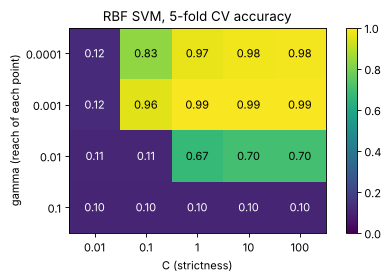

best: gamma=0.001, C=10, CV accuracy 0.9921
note: gamma='scale' for this data is 0.00043


In [10]:
Cs = [0.01, 0.1, 1, 10, 100]
gammas = [1e-4, 1e-3, 1e-2, 1e-1]
grid = np.zeros((len(gammas), len(Cs)))
for i, g in enumerate(gammas):
    for j, C in enumerate(Cs):
        grid[i, j] = cross_val_score(SVC(kernel='rbf', C=C, gamma=g), X_train, y_train, cv=5).mean()

fig, ax = plt.subplots(figsize=(6, 3.6))
im = ax.imshow(grid, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(Cs)), Cs); ax.set_yticks(range(len(gammas)), gammas)
ax.set_xlabel("C (strictness)"); ax.set_ylabel("gamma (reach of each point)")
for i in range(len(gammas)):
    for j in range(len(Cs)):
        ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", color="w" if grid[i, j] < .6 else "k")
ax.set_title("RBF SVM, 5-fold CV accuracy"); plt.colorbar(im); plt.tight_layout(); plt.show()
i, j = np.unravel_index(grid.argmax(), grid.shape)
print(f"best: gamma={gammas[i]}, C={Cs[j]}, CV accuracy {grid[i, j]:.4f}")
print("note: gamma='scale' for this data is", round(1 / (X_train.shape[1] * X_train.var()), 5))

How to read the grid:
- **gamma too large (0.1)**: each training image only influences a tiny bubble around itself, so the SVM memorises the training set and fails on new images (accuracy collapses).
- **gamma tiny and C tiny** (bottom-left): the boundary is so smooth and so tolerant of mistakes that it underfits.
- There is a broad "good region" (gamma 0.0001–0.001 with C ≥ 1, all about 97–99%); `gamma='scale'` (≈0.00043 here) lands inside it, which is why the default usually works.

## 7 · Is kNN really "slow for large datasets"? A timing experiment on real MNIST

The Key Concepts say kNN is *slow for large datasets because it compares with all samples*, and SVM is *computationally expensive for large datasets*. Both claims are about **different phases**, so we time **training** and **prediction** separately as the training set grows. 1,797 digits is too small to show anything, so we use real **MNIST** (28×28 = 784 features) downloaded by `torchvision` into `data/`. We predict the same 2,000 test images each time.

We add `LinearSVC`: a linear SVM that stores just one weight vector per class, so prediction is a single matrix multiplication.

In [11]:
from pathlib import Path
from sklearn.svm import LinearSVC

DATA = Path("data")
try:
    import io, contextlib
    from torchvision import datasets as tv_datasets
    with contextlib.redirect_stderr(io.StringIO()):     # hide the download progress bars
        mn_train = tv_datasets.MNIST(str(DATA), train=True, download=True)
        mn_test = tv_datasets.MNIST(str(DATA), train=False, download=True)
    HAVE_MNIST = True
except Exception as e:   # no torchvision, or offline
    print("Could not load MNIST (need torchvision and an internet connection the first time):", e)
    HAVE_MNIST = False

if HAVE_MNIST:
    Xm = mn_train.data.numpy().reshape(-1, 784).astype(np.float32) / 255   # scale 0-255 -> 0-1
    ym = mn_train.targets.numpy()
    Xq = mn_test.data.numpy().reshape(-1, 784).astype(np.float32)[:2000] / 255
    yq = mn_test.targets.numpy()[:2000]
    sizes = [1000, 5000, 10000, 20000]
    rows = []
    for n in sizes:
        for name, model in [("kNN k=5", KNeighborsClassifier(n_neighbors=5)),
                            ("SVC rbf", SVC(kernel='rbf')),
                            ("LinearSVC", LinearSVC(C=0.1))]:
            t0 = time.perf_counter(); model.fit(Xm[:n], ym[:n]); t_fit = time.perf_counter() - t0
            t0 = time.perf_counter(); acc = (model.predict(Xq) == yq).mean(); t_pred = time.perf_counter() - t0
            rows.append((n, name, t_fit, t_pred, acc))
            print(f"n_train={n:>6}  {name:10s} fit {t_fit:6.2f}s  predict 2000 {t_pred:5.2f}s  accuracy {acc:.3f}")

n_train=  1000  kNN k=5    fit   0.00s  predict 2000  0.06s  accuracy 0.807


n_train=  1000  SVC rbf    fit   0.13s  predict 2000  0.53s  accuracy 0.870
n_train=  1000  LinearSVC  fit   0.07s  predict 2000  0.03s  accuracy 0.822


n_train=  5000  kNN k=5    fit   0.00s  predict 2000  0.32s  accuracy 0.900


n_train=  5000  SVC rbf    fit   2.46s  predict 2000  2.03s  accuracy 0.929


n_train=  5000  LinearSVC  fit   0.51s  predict 2000  0.01s  accuracy 0.866


...

n_train= 10000  SVC rbf    fit   7.28s  predict 2000  3.03s  accuracy 0.945


n_train= 10000  LinearSVC  fit   1.59s  predict 2000  0.01s  accuracy 0.876


n_train= 20000  kNN k=5    fit   0.02s  predict 2000  1.32s  accuracy 0.940


n_train= 20000  SVC rbf    fit  20.89s  predict 2000  4.91s  accuracy 0.959


n_train= 20000  LinearSVC  fit   4.33s  predict 2000  0.01s  accuracy 0.882


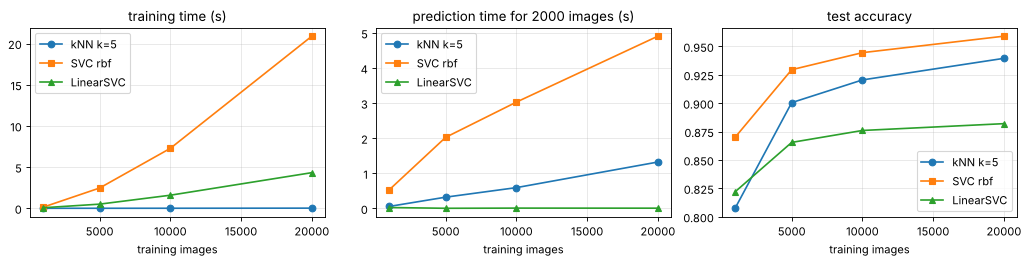

In [12]:
if HAVE_MNIST:
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
    for name, mk in [("kNN k=5", "o-"), ("SVC rbf", "s-"), ("LinearSVC", "^-")]:
        r = [row for row in rows if row[1] == name]
        ax[0].plot(sizes, [x[2] for x in r], mk, label=name)
        ax[1].plot(sizes, [x[3] for x in r], mk, label=name)
        ax[2].plot(sizes, [x[4] for x in r], mk, label=name)
    for a, t in zip(ax, ["training time (s)", "prediction time for 2000 images (s)", "test accuracy"]):
        a.set_title(t); a.set_xlabel("training images"); a.grid(alpha=.3); a.legend()
    plt.tight_layout(); plt.show()

**What the experiment shows (see the printed numbers above):**
- **kNN training is instant** (it only stores data), but its **prediction time grows with the training set**: it must compare every query with every stored image. That confirms the Key Concepts claim.
- **RBF SVM training grows much faster than linearly** (roughly quadratic) with the number of training images: that is the "computationally expensive for large datasets" con.
- **Surprise:** on this machine the RBF SVM was also **slower than kNN at prediction**. An RBF SVM compares each query with all its **support vectors** (thousands of them here), and kNN's brute-force search is done with fast matrix maths. So "kNN is slow, SVM is fast at prediction" is only true for a **linear** SVM stored as one weight vector (LinearSVC), which predicts almost instantly.
- **Accuracy:** more data helps every model; the RBF SVM is the most accurate of the three at every size.

Exact timings depend on your CPU, but the trends are what to remember.

## 8 · Mini project: handwritten digit recogniser

### 8a · The course version, and why its test proves nothing

The course function and test:

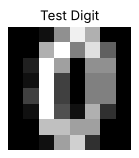

Predicted Label: 0
Is digits.images[10] in the TRAINING set? True


In [13]:
def recognize_digit(image):
    image = image.reshape(1, -1)          # 8x8 -> one row of 64 numbers, as the model expects
    prediction = svm.predict(image)
    return prediction[0]

# Test with a sample digit (course code)
sample_image = digits.images[10]
plt.figure(figsize=(2, 2)); plt.imshow(sample_image, cmap='gray'); plt.title("Test Digit"); plt.axis('off'); plt.show()
print("Predicted Label:", recognize_digit(digits.images[10]))

# Was image 10 one of the training images?
train_idx, test_idx = train_test_split(np.arange(len(X)), test_size=0.3, random_state=42)
print("Is digits.images[10] in the TRAINING set?", 10 in set(train_idx))

Image 10 **was in the training set**, so the model has already seen this exact image with its answer. Getting it right proves nothing (like testing a student on a question they were given the answer to). A fair test uses images the model **never saw**: the test split, or better still, a digit we draw ourselves.

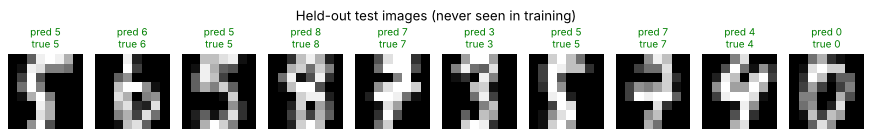

In [14]:
# Fair test: 10 random images from the held-out TEST split
rng = np.random.default_rng(1)
pick = rng.choice(len(X_test), 10, replace=False)
fig, axes = plt.subplots(1, 10, figsize=(11, 1.8))
for a, i in zip(axes, pick):
    p = recognize_digit(X_test[i])
    a.imshow(X_test[i].reshape(8, 8), cmap='gray'); a.axis('off')
    a.set_title(f"pred {p}\ntrue {y_test[i]}", color="green" if p == y_test[i] else "red", fontsize=9)
plt.suptitle("Held-out test images (never seen in training)"); plt.tight_layout(); plt.show()

### 8b · The mistakes: which digits get confused?

linear SVM got 11 of 540 test images wrong


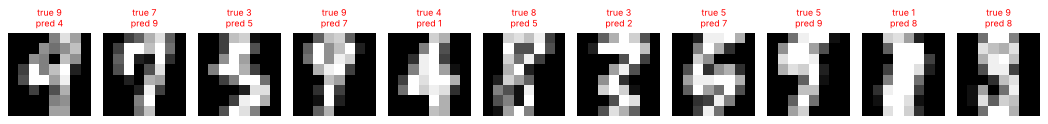

most common confusions (count, true -> predicted): [(np.int64(1), '9->8'), (np.int64(1), '9->7'), (np.int64(1), '9->4'), (np.int64(1), '8->5'), (np.int64(1), '7->9')]


In [15]:
wrong = np.where(y_pred_svm != y_test)[0]
print(f"linear SVM got {len(wrong)} of {len(y_test)} test images wrong")
fig, axes = plt.subplots(1, len(wrong), figsize=(1.2 * len(wrong), 1.8))
for a, i in zip(np.atleast_1d(axes), wrong):
    a.imshow(X_test[i].reshape(8, 8), cmap='gray'); a.axis('off')
    a.set_title(f"true {y_test[i]}\npred {y_pred_svm[i]}", fontsize=8, color="red")
plt.tight_layout(); plt.show()
cm = confusion_matrix(y_test, y_pred_svm)
np.fill_diagonal(cm, 0)
pairs = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if cm[i, j]), reverse=True)
print("most common confusions (count, true -> predicted):", [(c, f"{i}->{j}") for c, i, j in pairs[:5]])

The 11 mistakes are spread out (no pair of digits is confused more than once), and several are hard even for a human at 8×8 resolution. This is the real limit of pixel-based classifiers: they compare raw pixel patterns and have no idea about strokes or shapes.

### 8c · A digit *you* draw: the preprocessing that makes it work

A new image must look like the training data **in every way**, or the model fails:

| Training data (`load_digits`) | A typical drawing |
|---|---|
| 8×8 pixels | e.g. 200×200 pixels |
| values **0–16** | values 0–255 |
| **bright ink on dark background** (0 = background) | dark ink on white paper |
| digit **cropped and centred**, filling the box | digit anywhere on the page, any size |

The original dataset was made by scanning digits at 32×32 (black/white), then **counting ink pixels in each 4×4 block**, giving 8×8 blocks with counts 0–16. We copy that recipe exactly.

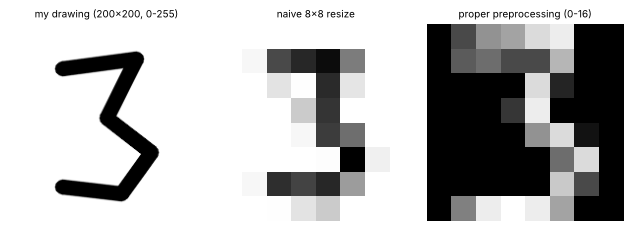

naive  -> predicted 2 | value range 68.0 - 255.0
proper -> predicted 3


In [16]:
def draw_digit_font(d, font=cv2.FONT_HERSHEY_SIMPLEX, thickness=16, scale=6):
    """Black digit on white 200x200 'paper', drawn with an OpenCV font."""
    canvas = np.full((200, 200), 255, np.uint8)
    cv2.putText(canvas, str(d), (40, 165), font, scale, 0, thickness, cv2.LINE_AA)
    return canvas

def draw_digit_strokes(d):
    """A rough 'hand-drawn' digit made from thick pen strokes (polylines), black on white."""
    strokes = {
        0: [[(100, 30), (60, 60), (55, 120), (80, 170), (120, 170), (145, 120), (140, 60), (100, 30)]],
        1: [[(80, 60), (110, 30), (110, 175)]],
        2: [[(55, 65), (90, 30), (135, 45), (140, 85), (60, 170), (150, 170)]],
        3: [[(55, 45), (130, 35), (100, 95), (145, 130), (115, 172), (55, 165)]],
        4: [[(120, 175), (120, 30), (50, 125), (155, 125)]],
        5: [[(140, 30), (70, 30), (62, 95), (125, 95), (140, 140), (105, 172), (55, 160)]],
        6: [[(130, 30), (75, 80), (60, 140), (95, 172), (138, 145), (118, 105), (65, 125)]],
        7: [[(50, 35), (150, 35), (90, 175)]],
        8: [[(100, 100), (60, 60), (100, 28), (140, 60), (100, 100), (55, 140), (100, 175), (145, 140), (100, 100)]],
        9: [[(135, 70), (100, 30), (60, 65), (95, 100), (135, 70), (125, 175)]],
    }
    canvas = np.full((200, 200), 255, np.uint8)
    for s in strokes[d]:
        cv2.polylines(canvas, [np.array(s, np.int32)], False, 0, 14, cv2.LINE_AA)
    return canvas

def preprocess_like_sklearn_digits(img):
    """Any grey image of ONE dark digit on light paper -> 8x8, values 0-16, like load_digits."""
    ink = (img < 128).astype(np.uint8)                 # 1) binarise and INVERT: ink = 1, paper = 0
    ys, xs = np.nonzero(ink)                           # 2) crop to the digit's bounding box
    ink = ink[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = ink.shape                                   # 3) pad to a square, keeping the aspect ratio, centred
    side = max(h, w)
    sq = np.zeros((side, side), np.uint8)
    sq[(side - h) // 2:(side - h) // 2 + h, (side - w) // 2:(side - w) // 2 + w] = ink
    sq32 = cv2.resize(sq, (32, 32), interpolation=cv2.INTER_NEAREST)   # 4) 32x32 black/white, like the original scans
    return sq32.reshape(8, 4, 8, 4).sum(axis=(1, 3)).astype(np.float64)  # 5) count ink in each 4x4 block -> 0..16

def naive_resize(img):
    """What beginners often do: just shrink the picture to 8x8. Wrong colours and wrong range."""
    return cv2.resize(img, (8, 8), interpolation=cv2.INTER_AREA).astype(np.float64)

raw = draw_digit_strokes(3)
steps = [raw, naive_resize(raw), preprocess_like_sklearn_digits(raw)]
titles = ["my drawing (200x200, 0-255)", "naive 8x8 resize", "proper preprocessing (0-16)"]
fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
for a, im, t in zip(ax, steps, titles):
    a.imshow(im, cmap='gray'); a.set_title(t, fontsize=9); a.axis('off')
plt.tight_layout(); plt.show()
print("naive  -> predicted", recognize_digit(naive_resize(raw)), "| value range", naive_resize(raw).min(), "-", naive_resize(raw).max())
print("proper -> predicted", recognize_digit(preprocess_like_sklearn_digits(raw)))

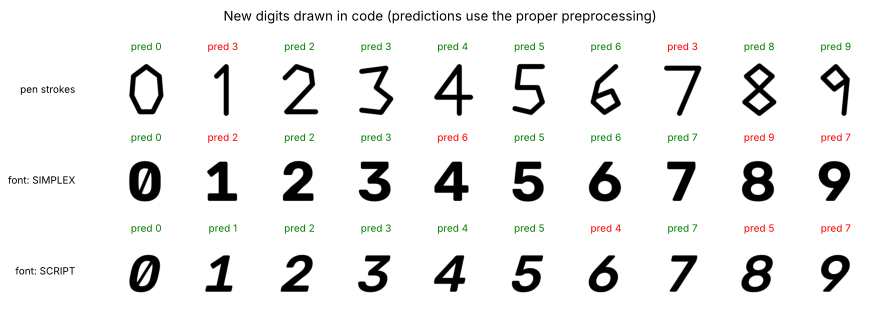

pen strokes   : naive resize 0/10 correct   |   proper preprocessing 8/10 correct
font: SIMPLEX : naive resize 0/10 correct   |   proper preprocessing 6/10 correct
font: SCRIPT  : naive resize 0/10 correct   |   proper preprocessing 7/10 correct


In [17]:
# Now all ten digits, three drawing styles, with and without preprocessing
styles = {
    "pen strokes": draw_digit_strokes,
    "font: SIMPLEX": lambda d: draw_digit_font(d, cv2.FONT_HERSHEY_SIMPLEX),
    "font: SCRIPT": lambda d: draw_digit_font(d, cv2.FONT_HERSHEY_SCRIPT_SIMPLEX, thickness=14),
}
fig, axes = plt.subplots(len(styles), 10, figsize=(11, 4))
score = {}
for r, (sname, fn) in enumerate(styles.items()):
    ok_naive = ok_proper = 0
    for d in range(10):
        img = fn(d)
        p_proper = recognize_digit(preprocess_like_sklearn_digits(img))
        p_naive = recognize_digit(naive_resize(img))
        ok_proper += p_proper == d; ok_naive += p_naive == d
        axes[r, d].imshow(img, cmap='gray'); axes[r, d].axis('off')
        axes[r, d].set_title(f"pred {p_proper}", fontsize=9, color="green" if p_proper == d else "red")
    axes[r, 0].text(-120, 100, sname, fontsize=9, ha="right", va="center")
    score[sname] = (ok_naive, ok_proper)
plt.suptitle("New digits drawn in code (predictions use the proper preprocessing)"); plt.tight_layout(); plt.show()
for s, (n, p) in score.items():
    print(f"{s:14s}: naive resize {n}/10 correct   |   proper preprocessing {p}/10 correct")

**What this shows:** without preprocessing the model got **0 of 30** right, worse than random guessing (the naive image has the wrong colours: a white background reads as "ink everywhere", and the values are 0–255 instead of 0–16). With the dataset's own recipe (invert, crop, centre, 32×32, count ink per 4×4 block), most new digits are recognised. The ones that still fail are drawn in a style that differs from the 1990s handwriting in the dataset (e.g. font shapes and the script font's slanted strokes); more varied training data, or a CNN (Day 15), handles this better.

**To try your own photo of a handwritten digit:** load it with `cv2.imread(path, cv2.IMREAD_GRAYSCALE)`, make sure it contains a single dark digit on light paper (crop it), and pass it through `preprocess_like_sklearn_digits` before `recognize_digit`. For uneven lighting, replace the fixed `img < 128` with Otsu's threshold: `cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)`.

## 9 · 🔧 What we changed from the course notebook, and why

| # | Course code | Problem | What we did |
|---|---|---|---|
| 1 | `SVC(kernel='linear', gamma='scale')` | `gamma` is only used by RBF/poly/sigmoid kernels. With a linear kernel it is **silently ignored** (we proved identical predictions with `gamma=1000`). Misleading, not a crash. | Used `SVC(kernel='linear')`, and showed where `gamma` really matters (RBF grid in 6b). |
| 2 | Mini project tests `digits.images[10]` | That image is **in the training split** (we checked), so a correct answer proves nothing. | Tested on held-out test images and on brand-new digits drawn in code. |
| 3 | Comment "Load MNIST digits dataset" | `load_digits()` is the 8×8 UCI digits set (1,797 images, values 0–16), not 28×28 MNIST. | Corrected the comment; used real MNIST for the timing experiment. |
| 4 | `recognize_digit` takes any image | It silently gives nonsense on any image not already in 8×8, 0–16, white-on-black format. | Added `preprocess_like_sklearn_digits` and showed the naive resize failing. |
| 5 | Only the report is printed | No confusion matrix, no look at the mistakes, `k` and `C`/`gamma` never tuned. | Added confusion matrices, misclassified examples, cross-validated k sweep and C/gamma grid. |

## 10 · Results, honestly

(All numbers are from the run above.)
- On the 540-image test split: **kNN (k=5) 99.26% (4 mistakes)**, **linear SVM 97.96% (11 mistakes)**, **RBF SVM 98.70% (7 mistakes)**. All three are excellent because this dataset is small, clean and low-resolution; the gap between them is a handful of images, which is within the noise of one random split.
- Cross-validation picked **k = 1** for kNN (98.65%); the RBF SVM's best cross-validated setting (gamma = 0.001, C = 10) reached 99.21%. In cross-validation the tuned RBF SVM is the best model, even though kNN won on the single test split.
- On real MNIST with 20,000 training images: kNN 94.0%, RBF SVM 95.9%, LinearSVC 88.2% on 2,000 test images. kNN predicted more slowly as the training set grew (confirming the textbook), but the RBF SVM was even slower at prediction on this CPU (about 5 s vs under 2 s for 2,000 queries); only LinearSVC is truly fast at prediction (about 0.01 s). RBF SVM training rose from about 0.1 s (1,000 images) to about 20 s (20,000 images). Exact times vary from run to run and machine to machine.
- On real MNIST (784 features), kNN predicts more slowly as the training set grows (confirming the textbook), but the RBF SVM was even slower at prediction on this CPU; only a linear SVM stored as weights (LinearSVC) is truly fast at prediction. RBF SVM training time grows steeply with data.
- On 30 digits drawn in code, proper preprocessing raised correct answers from **0/30** (naive resize) to **21/30**. The failures (e.g. a plain "1" read as 3 or 2, a bold "4" read as 6) are styles unlike the 1990s handwriting in the training set. The model is only as good as the match between new data and training data.

## 11 · Common errors and how to fix them

| Error / symptom | Cause | Fix |
|---|---|---|
| `ValueError: Expected 2D array, got 1D array instead` | Passing a single image (shape `(64,)` or `(8, 8)`) to `predict` | `model.predict(img.reshape(1, -1))`: one row = one sample |
| `ValueError: X has 784 features, but SVC is expecting 64 features` | New image not resized to the training size | Preprocess to 8×8 (64 values) for `load_digits`, 28×28 (784) for MNIST |
| Every drawn digit predicted as the same class | Colours inverted or wrong value range (0–255 vs 0–16) | Invert, crop, centre, rescale exactly like the training data |
| 100% accuracy that looks too good | Testing on training images (like the course's `digits.images[10]`) | Always evaluate on the held-out test split |
| `UndefinedMetricWarning` in the report | A class was never predicted (precision undefined) | Usually a sign of a broken model or tiny test set; check the data |
| RBF SVM accuracy ~10% | `gamma` far too large (or features not scaled) | Use `gamma='scale'`, tune with cross-validation, scale features |
| SVM training takes forever on big data | RBF SVM cost grows ~quadratically with samples | Use `LinearSVC`, a subset, or a CNN |

## 12 · Try this yourself

1. Change `n_neighbors` to 1 and to 50 in the course kNN cell. How does the report change? Explain using the k-sweep plot.
2. Use `KNeighborsClassifier(n_neighbors=5, weights='distance')` so closer neighbours get a bigger vote. Better or worse?
3. Run `train_test_split` with `random_state=0, 1, 2, 3`: how much do the accuracies move? What does this say about comparing 98.5% with 98.9%?
4. Scale the features with `StandardScaler` before the SVM (`from sklearn.pipeline import make_pipeline`). Does the RBF SVM change?
5. Draw a digit in Paint (black on white), save it as `my_digit.png`, and run it through `preprocess_like_sklearn_digits` and `recognize_digit`.
6. Rotate a test digit by 20° (`scipy.ndimage.rotate`) and classify it. Why does a pixel-based classifier struggle?

## 13 · Viva questions (with short model answers)

1. **What is supervised learning?** Learning from examples that come with the correct answer (label), so the model can predict labels for new inputs. Digit recognition is supervised: image → digit 0–9.
2. **How does kNN classify a new image?** Compute its distance to every training image, take the k closest, and return the majority label among them.
3. **Why is kNN called a "lazy" learner?** `fit` only stores the data; all computation happens at prediction time. So training is instant but prediction cost grows with the size of the training set.
4. **What happens with k = 1 and with a very large k?** k = 1 memorises the training set and is sensitive to noise (overfitting); a very large k averages over far-away points and blurs classes (underfitting). Choose k by cross-validation; odd k avoids ties.
5. **What is a support vector?** A training point lying on or inside the margin; only these points determine the SVM's boundary.
6. **What do `C` and `gamma` control?** `C` trades margin width against training errors (high C = strict, risk of overfitting). `gamma` sets how far one point's influence reaches in the RBF kernel (high gamma = wiggly boundary, overfitting).
7. **What is the kernel trick?** Computing similarities as if the data were mapped into a higher-dimensional space, without actually building that space, so a linear separator there becomes a curved boundary in the original space.
8. **Why is `gamma='scale'` with `kernel='linear'` pointless?** A linear kernel is just a dot product; it has no gamma, so the setting is ignored.
9. **Define precision, recall, f1 and support.** Precision = TP/(TP+FP), recall = TP/(TP+FN), f1 = their harmonic mean, support = number of true samples of the class in the test set.
10. **Macro vs weighted average?** Macro averages classes equally; weighted averages by each class's support.
11. **Why must we test on held-out data?** The goal is performance on new images; testing on training images measures memory, not generalisation.
12. **Why do we need preprocessing for a new drawing?** The model only knows the training format (8×8, 0–16, bright ink on dark, centred); any mismatch moves the image to a region of feature space with no similar training examples.
13. **What is the difference between `load_digits` and MNIST?** load_digits: 1,797 images, 8×8, values 0–16. MNIST: 70,000 images, 28×28, values 0–255.
14. **Which is faster to predict with, kNN or SVM?** It depends: kNN's prediction cost grows with training size; an RBF SVM's grows with the number of support vectors (in our MNIST test it was even slower than kNN); a linear SVM stored as weights is the fastest.
15. **Why not use kNN/SVM on raw pixels for everything?** Raw pixels are not invariant to shifts, rotation, scale or lighting, and the cost grows with data; that is why we move to features (Day 12) and CNNs (Day 15).